# 📊 Business Insights Dashboard - Exploratory Data Analysis

## Project Overview

This notebook performs Exploratory Data Analysis (EDA) on the Sample Superstore dataset.

The objective is to identify business trends, customer behavior, regional performance, and product performance through data visualization.

The insights obtained here will later be used to build an interactive Streamlit Business Dashboard with Machine Learning-based Sales Prediction.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/Sample - Superstore.csv", encoding="latin1")

df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Display charts inside notebook
%matplotlib inline

# Better chart style
sns.set_style("whitegrid")

In [4]:
df = pd.read_csv("../data/Sample - Superstore.csv", encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [13]:
# Convert date columns
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Feature Engineering
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Day"] = df["Order Date"].dt.day
df["Day Name"] = df["Order Date"].dt.day_name()

print("Preprocessing Completed Successfully!")

Preprocessing Completed Successfully!


In [6]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["Product Name"].nunique()

print(f"Total Sales      : ${total_sales:,.2f}")
print(f"Total Profit     : ${total_profit:,.2f}")
print(f"Total Orders     : {total_orders}")
print(f"Total Customers  : {total_customers}")
print(f"Total Products   : {total_products}")

Total Sales      : $2,297,200.86
Total Profit     : $286,397.02
Total Orders     : 5009
Total Customers  : 793
Total Products   : 1850


# 📊 Sales Analysis

The objective of this section is to analyze the company's sales performance across different business dimensions such as category, region and time.

## 1. Sales by Category

### Objective

To identify which product category contributes the highest sales.

In [7]:
category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

category_sales

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

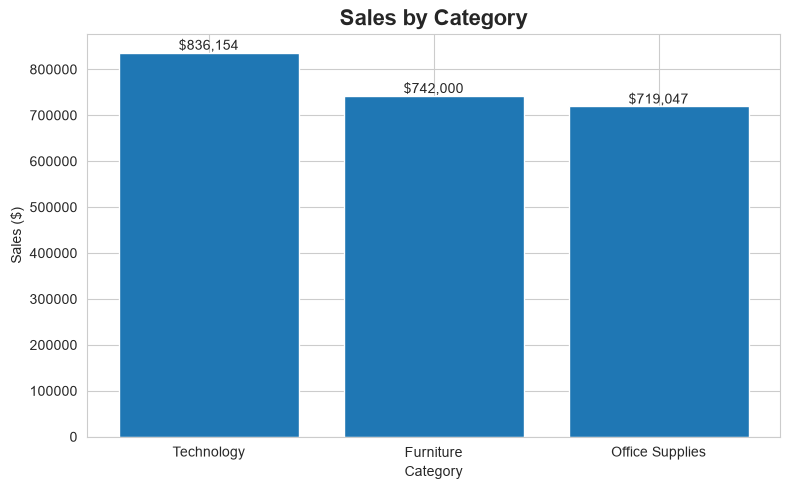

In [8]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    category_sales.index,
    category_sales.values
)

plt.title(
    "Sales by Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Category")
plt.ylabel("Sales ($)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()

## 2. Sales by Region

### Objective

To identify the highest and lowest performing sales regions.

In [7]:
import pandas as pd
df = pd.read_csv("../data/Sample - Superstore.csv", encoding="latin1")
region_sales = (
    df.groupby("Region")["Sales"]
      .sum().sort_values(ascending=False)
      
)

region_sales

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64

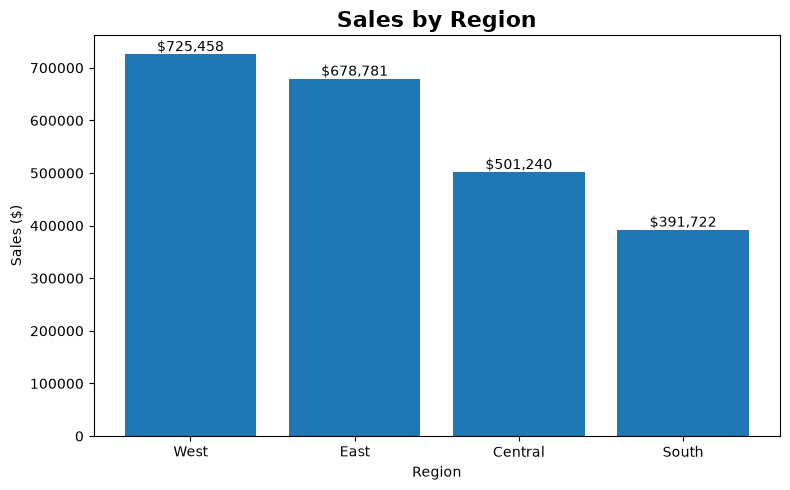

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))

bars = plt.bar(
    region_sales.index,
    region_sales.values
)

plt.title(
    "Sales by Region",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Region")
plt.ylabel("Sales ($)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()

### Business Insight

The West region generated the highest sales.

### Possible Reason

Higher customer demand and a larger customer base contributed to stronger sales performance.

### Recommendation

Study the successful sales strategies used in the West region and apply them to lower-performing regions.

## 3. Monthly Sales Trend

### Objective

To understand how sales change over time and identify seasonal patterns.

In [14]:
print(df.columns)
df.head()


Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year',
       'Month', 'Month Name', 'Day', 'Day Name'],
      dtype='str')


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Day,Day Name
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November,8,Tuesday
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November,8,Tuesday
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June,12,Sunday
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October,11,Sunday
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October,11,Sunday


In [15]:
month_order = [
    "January","February","March","April",
    "May","June","July","August",
    "September","October","November","December"
]

monthly_sales = (
    df.groupby("Month Name")["Sales"]
      .sum()
      .reindex(month_order)
)

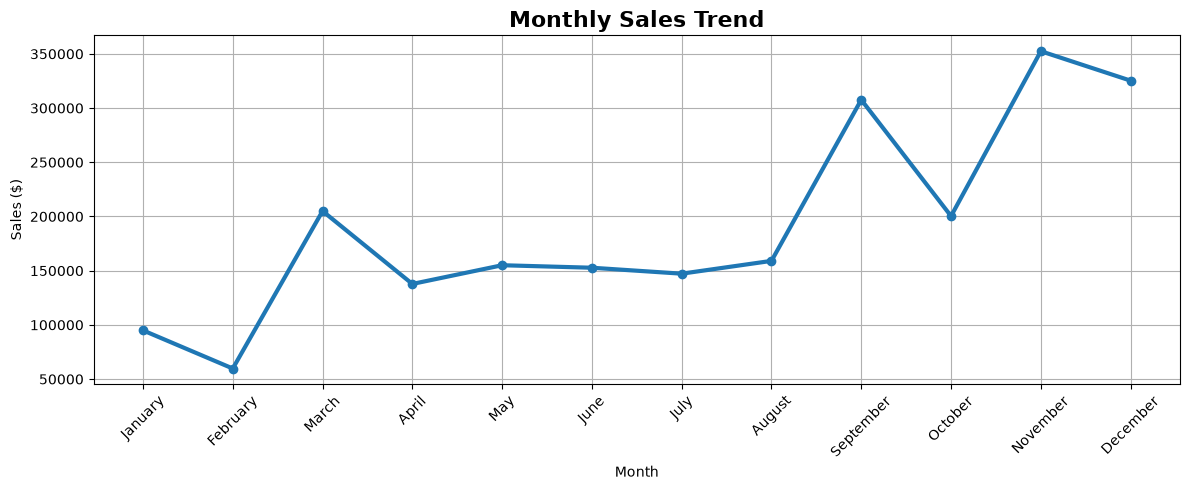

In [16]:
plt.figure(figsize=(12,5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=3
)

plt.title(
    "Monthly Sales Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Sales ($)")

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.show()

### Business Insight

Sales fluctuate throughout the year, indicating seasonal demand patterns.

### Possible Reason

Festive seasons, promotional campaigns and customer buying behavior influence monthly sales.

### Recommendation

Plan inventory and marketing campaigns ahead of high-demand months to maximize revenue.

## 4. Year-wise Sales

### Objective

To analyze how the company's sales have grown over the years.

In [17]:
yearly_sales = (
    df.groupby("Year")["Sales"]
      .sum()
      .sort_index()
)

yearly_sales

Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64

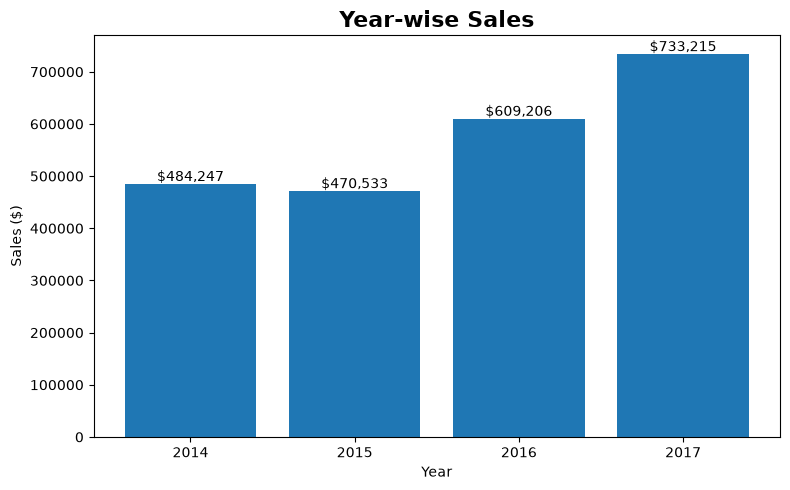

In [18]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    yearly_sales.index.astype(str),
    yearly_sales.values
)

plt.title(
    "Year-wise Sales",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Sales ($)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Business Insight

The company's sales have shown an upward trend over the years.

### Possible Reason

An expanding customer base, increased product demand, and improved sales strategies may have contributed to the growth.

### Recommendation

Continue investing in successful sales channels while monitoring year-over-year growth to sustain business performance.

## 5. Top 10 Products by Sales

### Objective

To identify the products contributing the highest sales.

In [19]:
top_products = df.groupby("Product Name")["Sales"].sum().sort_values(ascending = False).head(10);
print(top_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


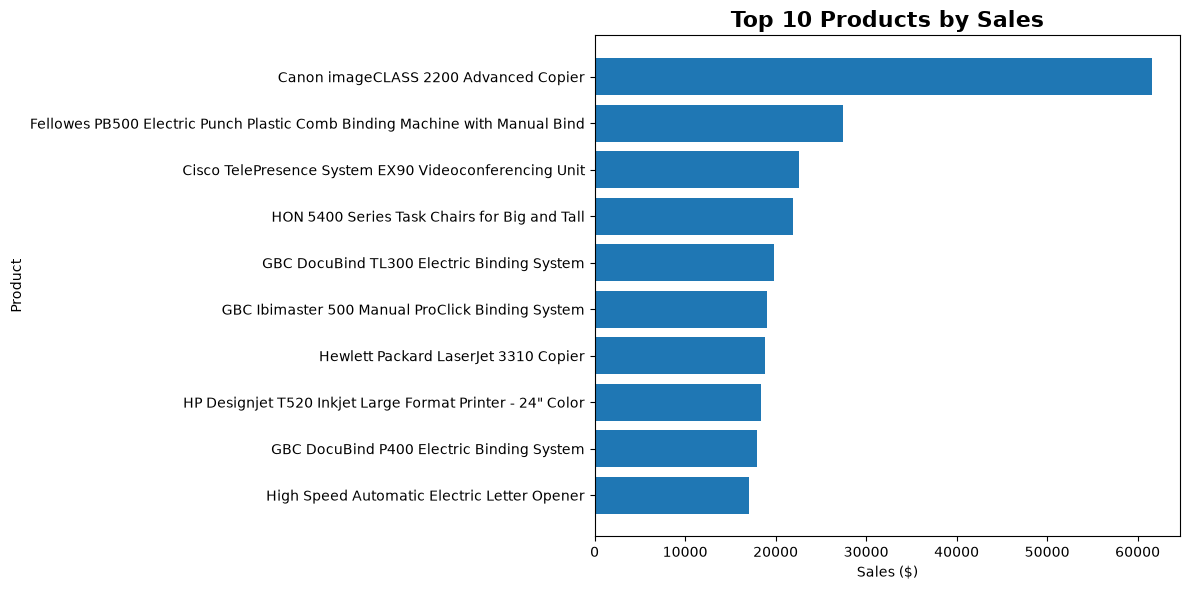

In [20]:
plt.figure(figsize=(12,6))

bars = plt.barh(
    top_products.index,
    top_products.values
)

plt.title(
    "Top 10 Products by Sales",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Sales ($)")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [21]:
top_subcategories = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending = False)
print(top_subcategories)

Sub-Category
Phones         330007.0540
Chairs         328449.1030
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91705.1640
Paper           78479.2060
Supplies        46673.5380
Art             27118.7920
Envelopes       16476.4020
Labels          12486.3120
Fasteners        3024.2800
Name: Sales, dtype: float64


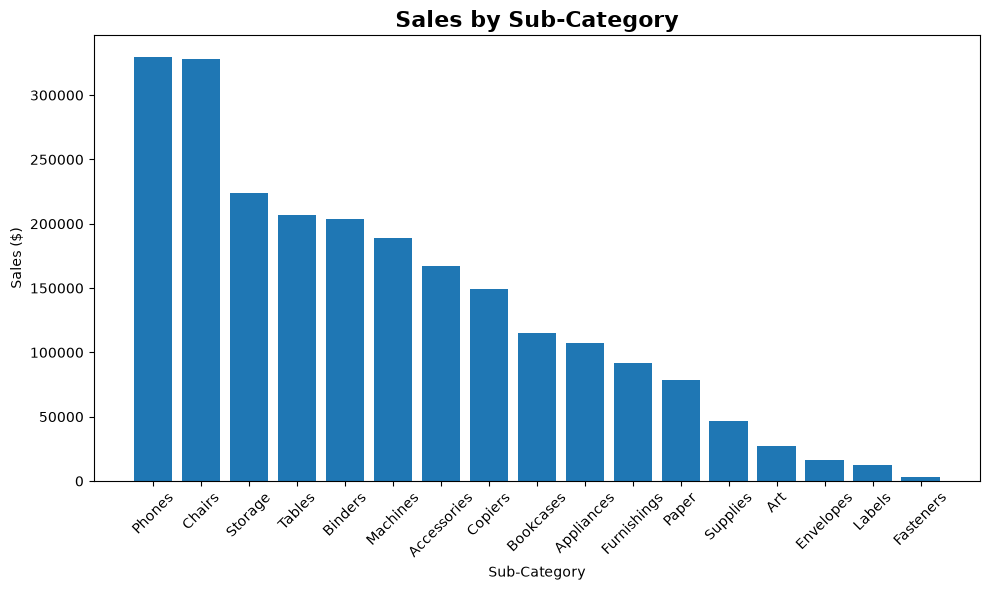

In [24]:
plt.figure(figsize=(10,6))

bars = plt.bar(
    top_subcategories.index,
    top_subcategories.values
)

plt.title(
    "Sales by Sub-Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Sub-Category")
plt.ylabel("Sales ($)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

# 💰 Profit Analysis

The objective of this section is to analyze the company's profitability across different categories, regions, and time periods.

## 1. Profit by Category

### Objective

To identify which product categories generate the highest profit.

In [25]:
category_profit = (
    df.groupby("Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

category_profit

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64

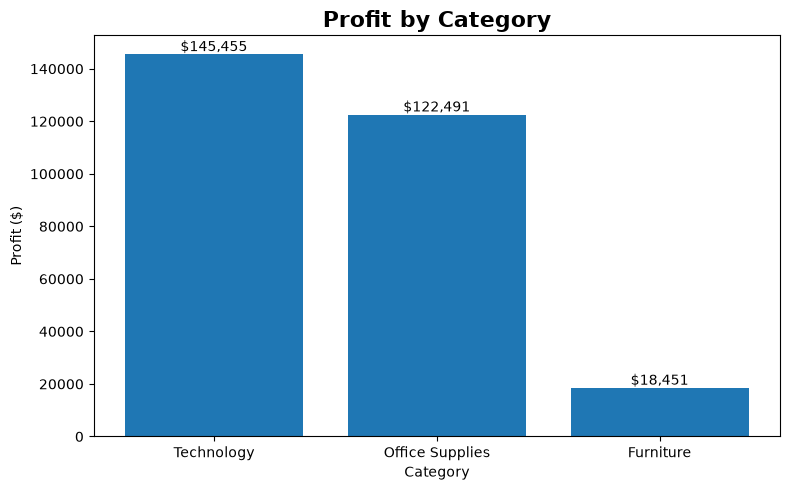

In [26]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    category_profit.index,
    category_profit.values
)

plt.title(
    "Profit by Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Category")
plt.ylabel("Profit ($)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [27]:
region_profit = (
    df.groupby("Region")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

region_profit

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64

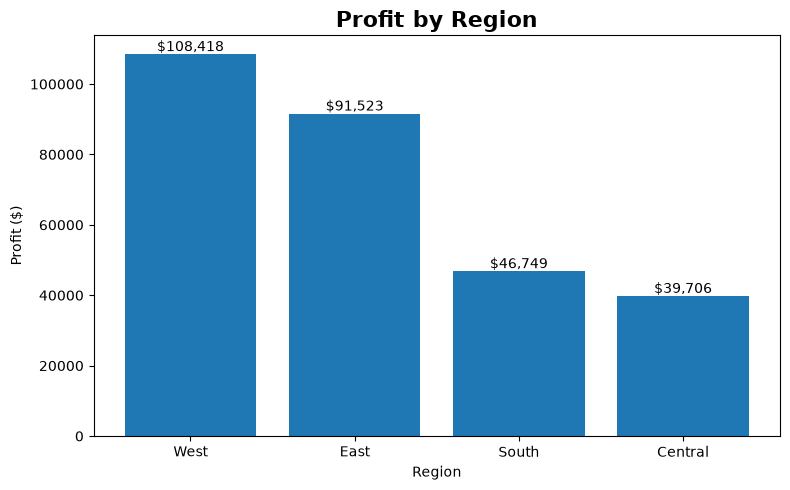

In [28]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    region_profit.index,
    region_profit.values
)

plt.title(
    "Profit by Region",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Region")
plt.ylabel("Profit ($)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [29]:
month_order = [
    "January","February","March","April",
    "May","June","July","August",
    "September","October","November","December"
]

monthly_profit = (
    df.groupby("Month Name")["Profit"]
      .sum()
      .reindex(month_order)
)

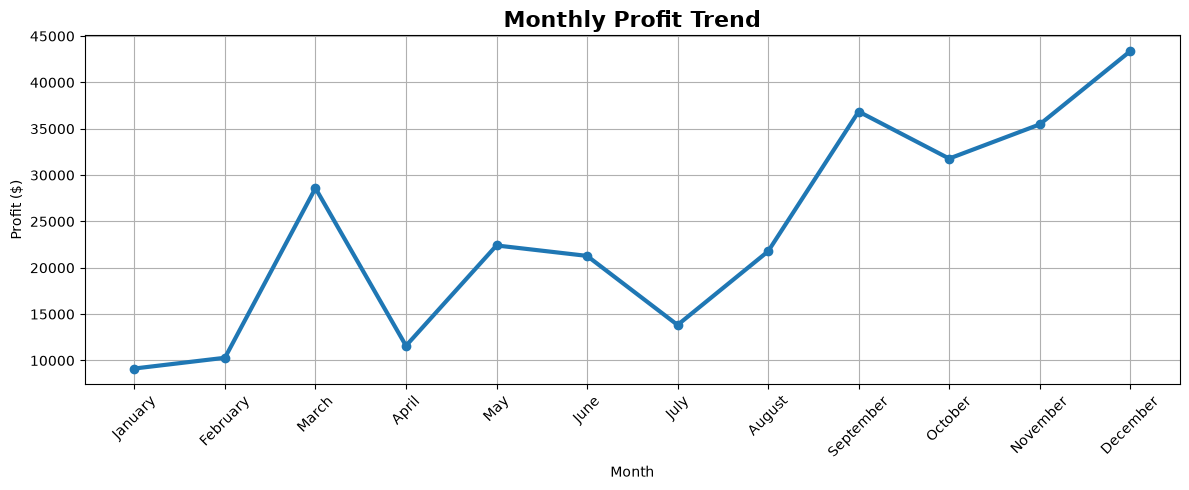

In [30]:
plt.figure(figsize=(12,5))

plt.plot(
    monthly_profit.index,
    monthly_profit.values,
    marker="o",
    linewidth=3
)

plt.title(
    "Monthly Profit Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Profit ($)")

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.show()

In [31]:
category_profit

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64

In [32]:
subcategory_profit = (
    df.groupby("Sub-Category")["Profit"]
      .sum()
      .sort_values()
)

subcategory_profit

Sub-Category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13059.1436
Appliances     18138.0054
Storage        21278.8264
Chairs         26590.1663
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: Profit, dtype: float64

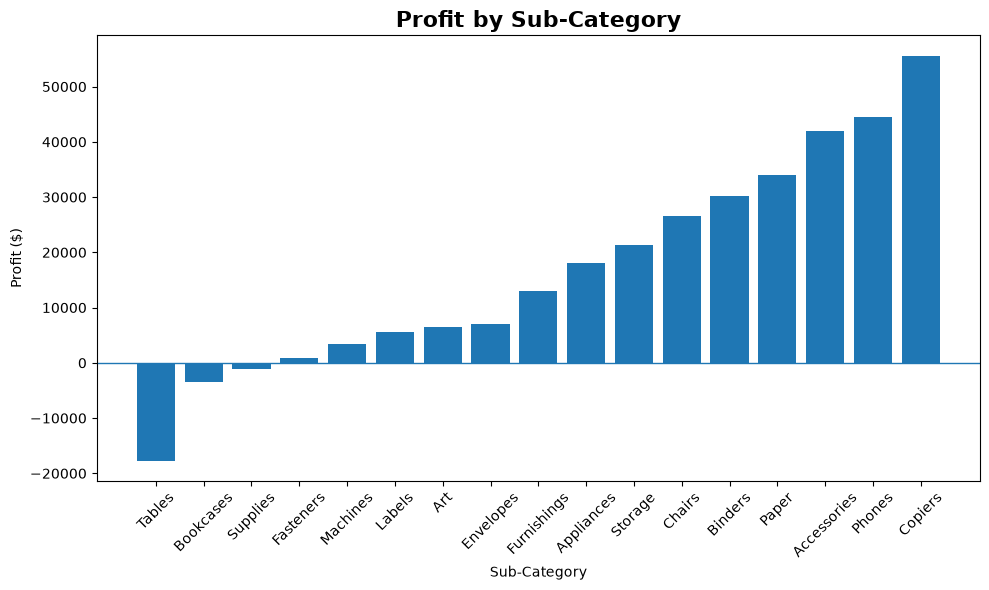

In [33]:
plt.figure(figsize=(10,6))

bars = plt.bar(
    subcategory_profit.index,
    subcategory_profit.values
)

plt.title(
    "Profit by Sub-Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Sub-Category")
plt.ylabel("Profit ($)")

plt.xticks(rotation=45)

plt.axhline(0, linewidth=1)

plt.tight_layout()

plt.show()

# 👥 Customer Analysis

The objective of this section is to analyze customer purchasing behavior, identify high-value customers, and understand which customer segments contribute the most to the business.

In [34]:
top_customers = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending = False).head(10)
top_customers

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

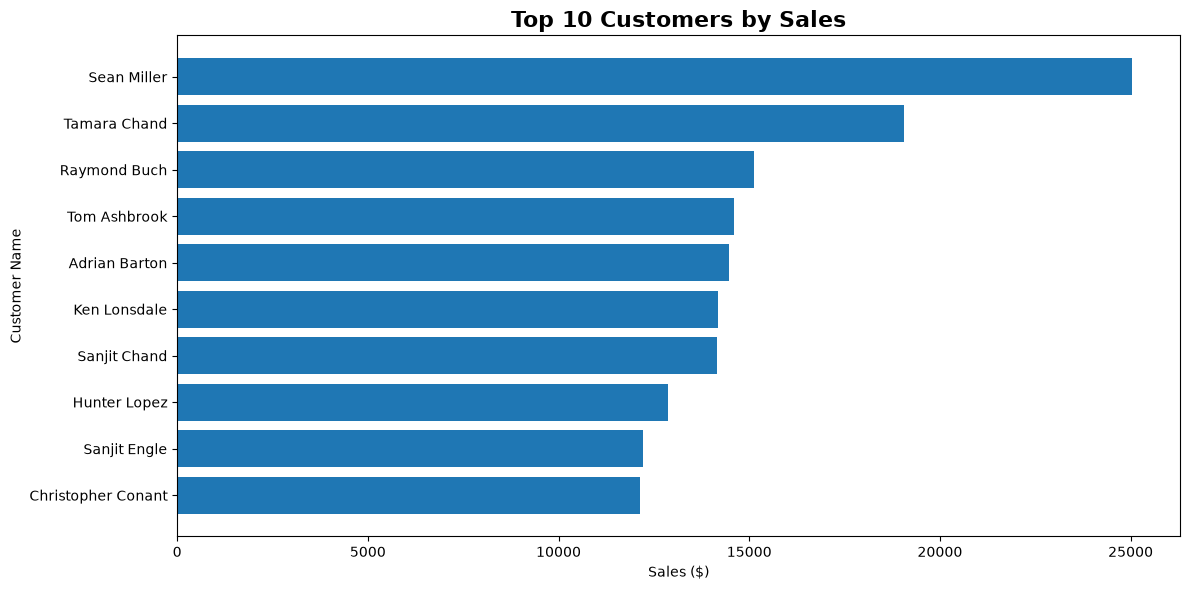

In [35]:
plt.figure(figsize=(12,6))

bars = plt.barh(
    top_customers.index,
    top_customers.values
)

plt.title(
    "Top 10 Customers by Sales",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Sales ($)")
plt.ylabel("Customer Name")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

## 2. Sales by Customer Segment

### Objective

To identify which customer segment contributes the highest sales.

In [36]:
segment_sales = (
    df.groupby("Segment")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

segment_sales

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64

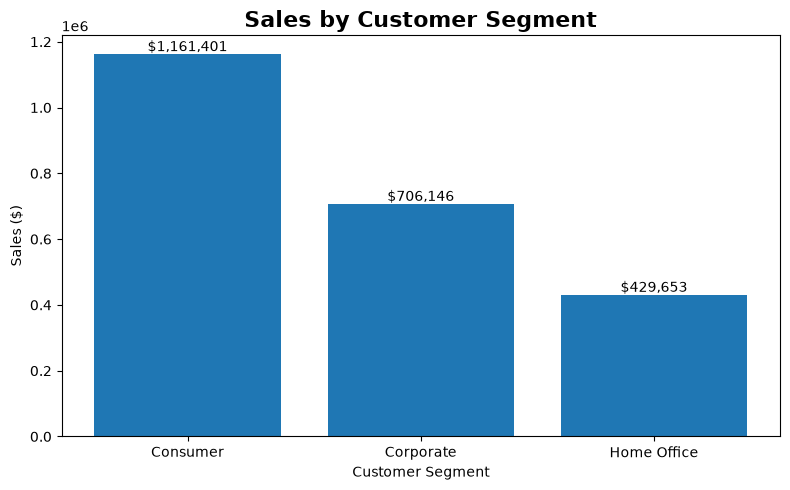

In [37]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    segment_sales.index,
    segment_sales.values
)

plt.title(
    "Sales by Customer Segment",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Segment")
plt.ylabel("Sales ($)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()

In [38]:
segment_profit = (
    df.groupby("Segment")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

segment_profit

Segment
Consumer       134119.2092
Corporate       91979.1340
Home Office     60298.6785
Name: Profit, dtype: float64

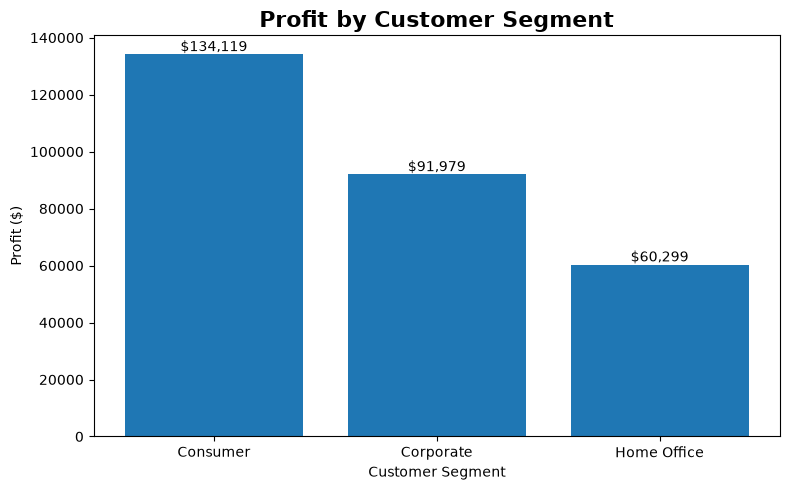

In [39]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    segment_profit.index,
    segment_profit.values
)

plt.title(
    "Profit by Customer Segment",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Segment")
plt.ylabel("Profit ($)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()

Average Order Value by Segment

This answers:

Which customer segment spends the most per order?

In [40]:
avg_segment_sales = (
    df.groupby("Segment")["Sales"]
      .mean()
      .sort_values(ascending=False)
)

avg_segment_sales

Segment
Home Office    240.972041
Corporate      233.823300
Consumer       223.733644
Name: Sales, dtype: float64

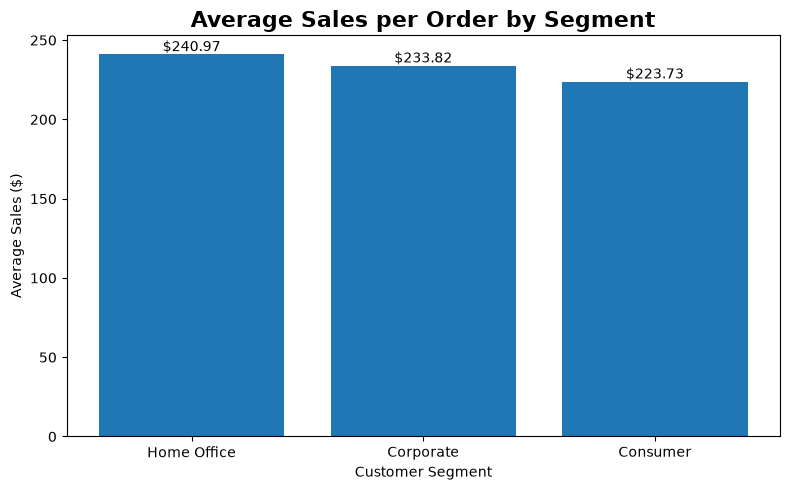

In [41]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    avg_segment_sales.index,
    avg_segment_sales.values
)

plt.title(
    "Average Sales per Order by Segment",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Segment")
plt.ylabel("Average Sales ($)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"${height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()

# 🌍 Regional & Shipping Analysis

This section analyzes the geographical distribution of sales and profit, along with customer shipping preferences. The insights help identify high-performing locations and understand the impact of shipping methods on business performance.

## 1. Top 10 States by Sales

### Objective

To identify the states contributing the highest sales revenue.

In [42]:
top_states = df.groupby("State")["Sales"].sum().sort_values(ascending = False).head(10)
top_states

State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Florida          89473.7080
Illinois         80166.1010
Ohio             78258.1360
Michigan         76269.6140
Virginia         70636.7200
Name: Sales, dtype: float64

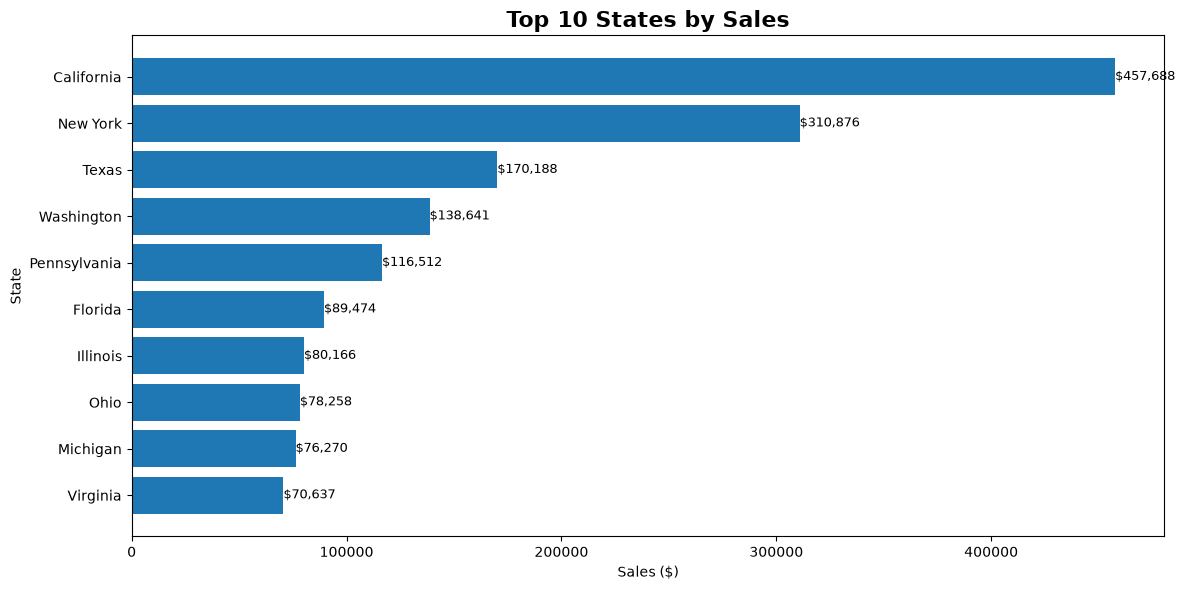

In [43]:
plt.figure(figsize=(12,6))

bars = plt.barh(
    top_states.index,
    top_states.values
)

plt.title(
    "Top 10 States by Sales",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Sales ($)")
plt.ylabel("State")

plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()

    plt.text(
        width,
        bar.get_y() + bar.get_height()/2,
        f"${width:,.0f}",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()

plt.show()

In [44]:
top_profit_states = (
    df.groupby("State")["Profit"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_profit_states

State
California    76381.3871
New York      74038.5486
Washington    33402.6517
Michigan      24463.1876
Virginia      18597.9504
Indiana       18382.9363
Georgia       16250.0433
Kentucky      11199.6966
Minnesota     10823.1874
Delaware       9977.3748
Name: Profit, dtype: float64

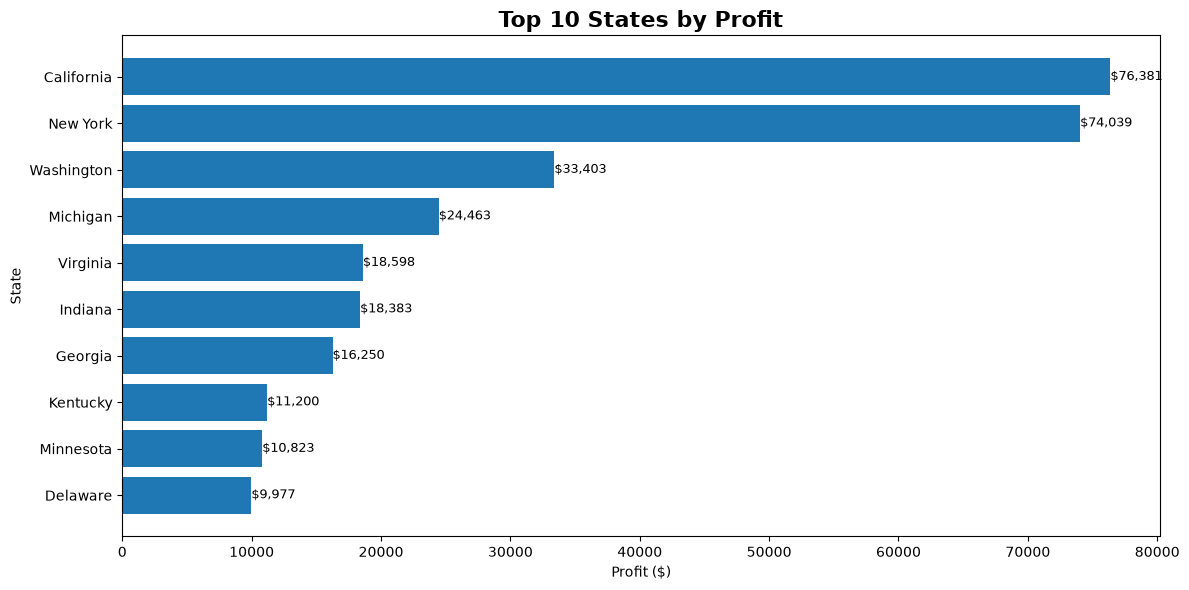

In [45]:
plt.figure(figsize=(12,6))

bars = plt.barh(
    top_profit_states.index,
    top_profit_states.values
)

plt.title(
    "Top 10 States by Profit",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Profit ($)")
plt.ylabel("State")

plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()

    plt.text(
        width,
        bar.get_y()+bar.get_height()/2,
        f"${width:,.0f}",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()

plt.show()

## 3. Shipping Mode Distribution

### Objective

To analyze the usage of different shipping modes.(which one usually the customers prefer)

In [46]:
shipping_mode = df["Ship Mode"].value_counts()

shipping_mode

Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64

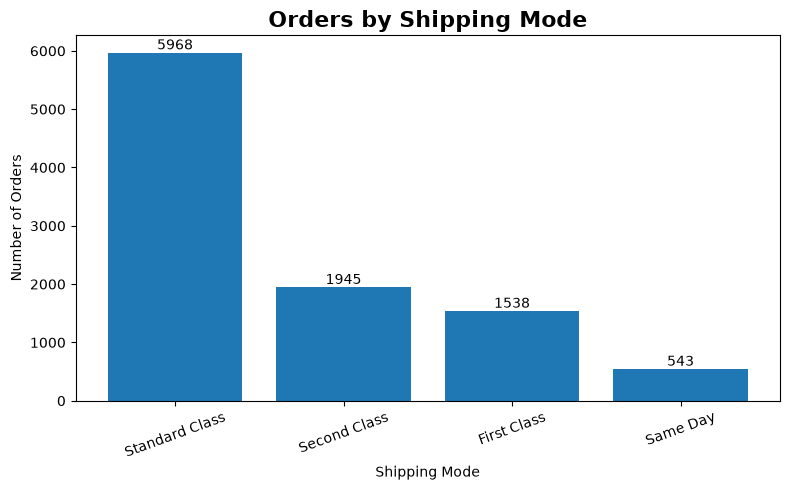

In [47]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    shipping_mode.index,
    shipping_mode.values
)

plt.title(
    "Orders by Shipping Mode",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Shipping Mode")
plt.ylabel("Number of Orders")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"{height}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

In [48]:
shipping_sales = (
    df.groupby("Ship Mode")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

shipping_sales

Ship Mode
Standard Class    1.358216e+06
Second Class      4.591936e+05
First Class       3.514284e+05
Same Day          1.283631e+05
Name: Sales, dtype: float64

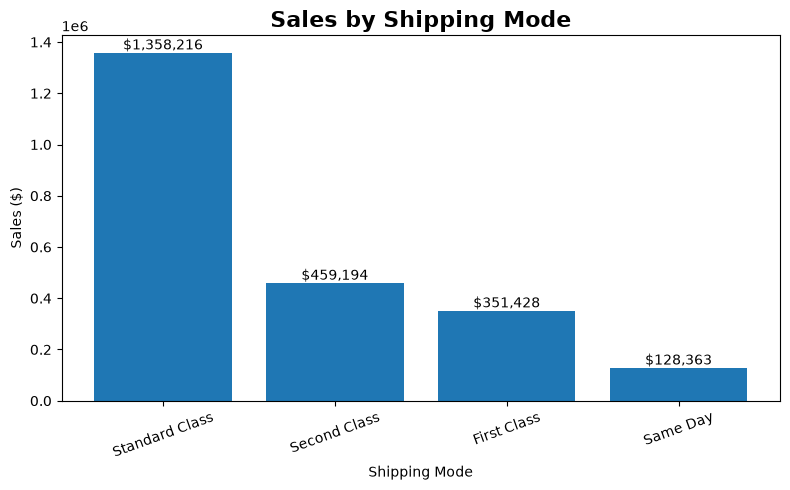

In [49]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    shipping_sales.index,
    shipping_sales.values
)

plt.title(
    "Sales by Shipping Mode",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Shipping Mode")
plt.ylabel("Sales ($)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"${height:,.0f}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

In [50]:
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df["Shipping Days"].head()

0    3
1    3
2    4
3    7
4    7
Name: Shipping Days, dtype: int64

In [51]:
avg_shipping_days = (
    df.groupby("Ship Mode")["Shipping Days"]
      .mean()
      .sort_values()
)

avg_shipping_days

Ship Mode
Same Day          0.044199
First Class       2.182705
Second Class      3.238046
Standard Class    5.006535
Name: Shipping Days, dtype: float64

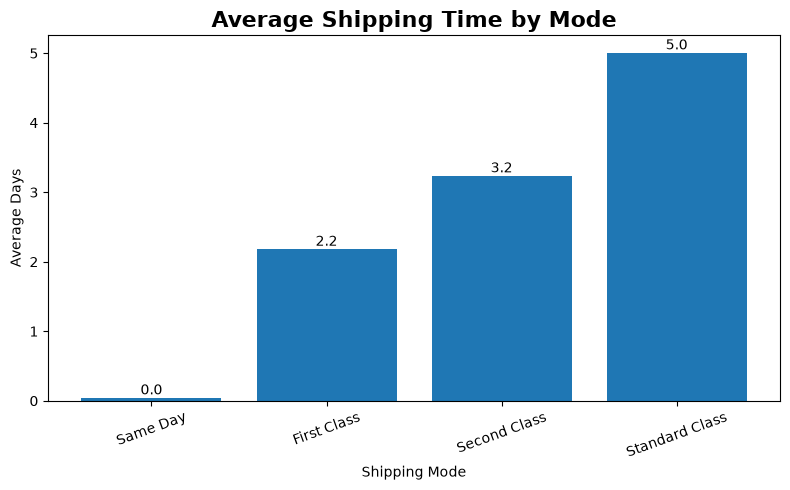

In [52]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    avg_shipping_days.index,
    avg_shipping_days.values
)

plt.title(
    "Average Shipping Time by Mode",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Shipping Mode")
plt.ylabel("Average Days")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"{height:.1f}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

# 🔍 Advanced Business Insights

This section explores deeper business patterns by analyzing discounts, profit margins, loss-making products, and relationships between important business variables.

Analysis 1: Discount vs Profit (One of the Most Important)
Why are we doing this?

Imagine you're the CEO.

You ask:

"Are bigger discounts actually helping the business?"

This chart answers exactly that.

## 1. Discount vs Profit

### Objective

To understand how discounts affect profitability.

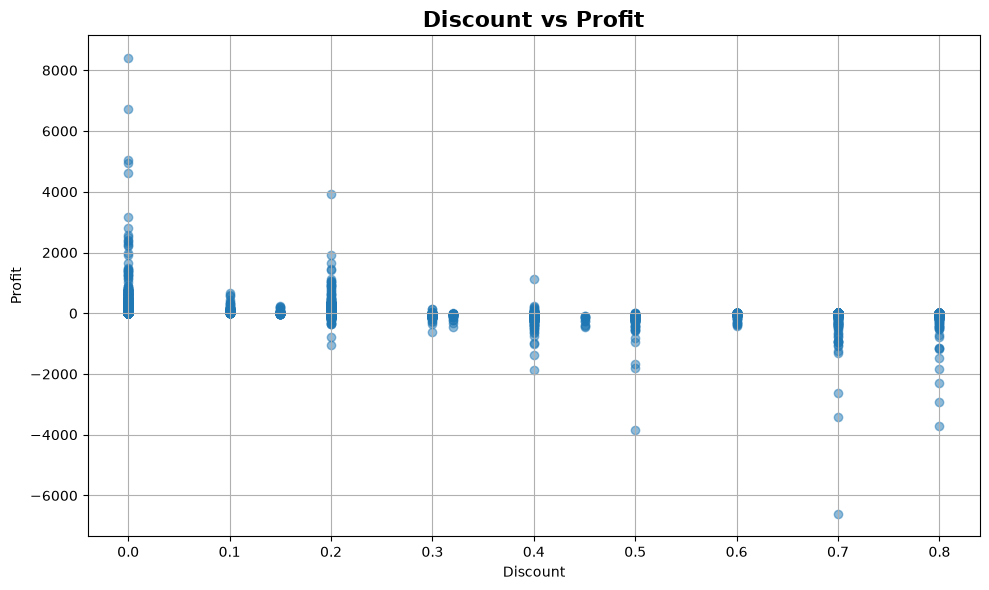

In [53]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["Discount"],
    df["Profit"],
    alpha=0.5
)

plt.title(
    "Discount vs Profit",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Discount")
plt.ylabel("Profit")

plt.grid(True)

plt.tight_layout()

plt.show()

### Business Insight

Higher discounts generally lead to lower profits and, in some cases, even losses.

### Possible Reason

Large discounts reduce the profit margin on products.

### Recommendation

Avoid excessive discounting and optimize promotional strategies based on product profitability.

## 2. Top 10 Loss-Making Products

### Objective

To identify products causing the highest financial losses.

In [54]:
loss_products = (
    df.groupby("Product Name")["Profit"]
      .sum()
      .sort_values()
      .head(10)
)

loss_products

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64

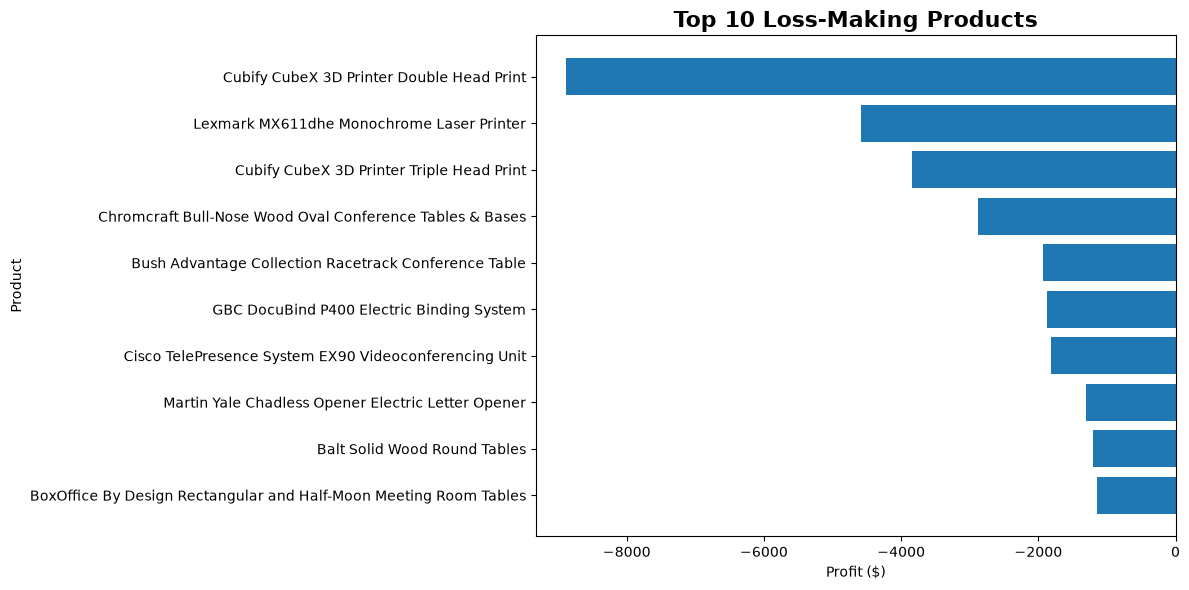

In [55]:
plt.figure(figsize=(12,6))

bars = plt.barh(
    loss_products.index,
    loss_products.values
)

plt.title(
    "Top 10 Loss-Making Products",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Profit ($)")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

Profit Margin = Profit / Sales × 100

In [56]:
profit_margin = (
    df.groupby("Category")[["Sales","Profit"]]
      .sum()
)

profit_margin["Profit Margin (%)"] = (
    profit_margin["Profit"] /
    profit_margin["Sales"]
) * 100

profit_margin

,Sales,Profit,Profit Margin (%)
Category,,,
Furniture,741999.7953,18451.2728,2.486695
Office Supplies,719047.0320,122490.8008,17.035158
Technology,836154.0330,145454.9481,17.395712


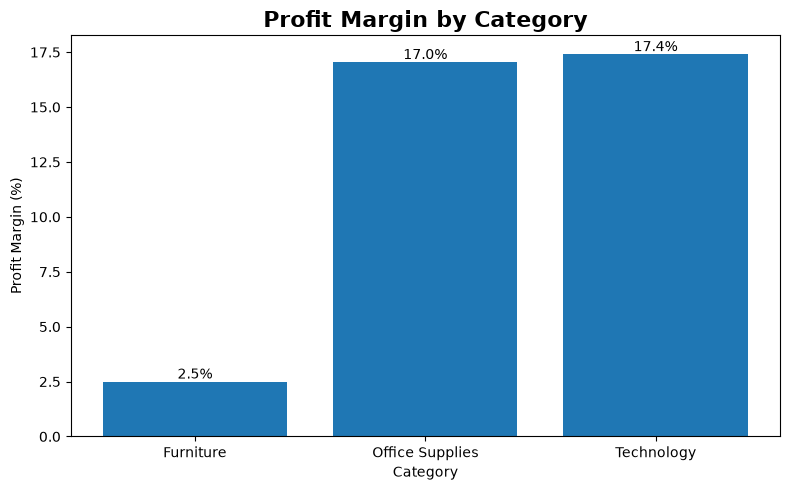

In [57]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    profit_margin.index,
    profit_margin["Profit Margin (%)"]
)

plt.title(
    "Profit Margin by Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height,
        f"{height:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()

## 4. Correlation Analysis

### Objective

To understand relationships among numerical business variables.

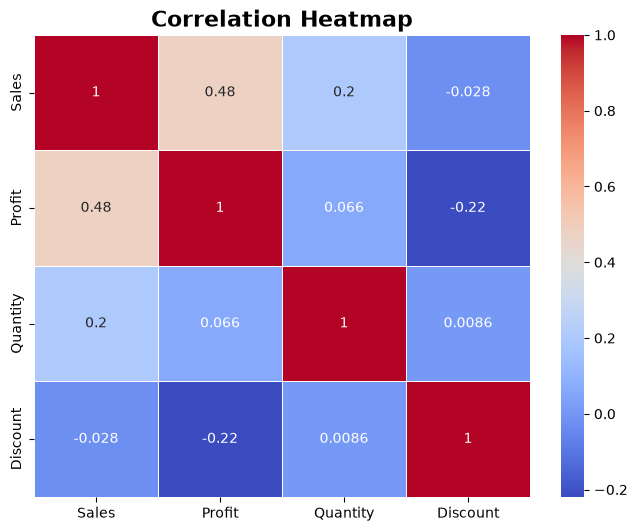

In [58]:
import seaborn as sns

plt.figure(figsize=(8,6))

sns.heatmap(
    df[
        [
            "Sales",
            "Profit",
            "Quantity",
            "Discount"
        ]
    ].corr(),
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title(
    "Correlation Heatmap",
    fontsize=16,
    fontweight="bold"
)

plt.show()

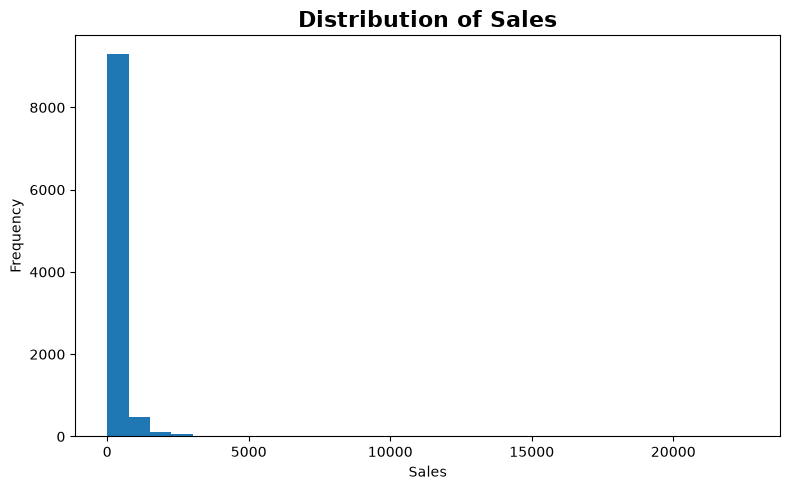

In [59]:
plt.figure(figsize=(8,5))

plt.hist(
    df["Sales"],
    bins=30
)

plt.title(
    "Distribution of Sales",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Sales")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

In [60]:
discount_category = (
    df.groupby("Category")["Discount"]
      .mean()
      .sort_values(ascending=False)
)

discount_category

Category
Furniture          0.173923
Office Supplies    0.157285
Technology         0.132323
Name: Discount, dtype: float64

# 📋 Executive Summary

## Key Findings

### Sales
- Technology generated the highest sales.
- The West region contributed the highest revenue.
- California emerged as the top-performing state.

### Profit
- Technology was the most profitable category.
- Some sub-categories and products generated consistent losses.
- Higher discounts showed a negative impact on profit.

### Customers
- Consumer was the largest and most profitable customer segment.
- A small number of customers contributed significantly to total sales.

### Shipping
- Standard Class handled the majority of orders.
- Shipping times varied across different shipping modes.

## Business Recommendations

1. Reduce excessive discounts on low-margin products.
2. Focus marketing efforts on high-performing regions and customer segments.
3. Review pricing strategies for loss-making products.
4. Strengthen inventory planning for top-selling categories.
5. Monitor profit margins alongside sales to ensure sustainable growth.